In [1]:
import sys
sys.path.append("/Users/austindestcroix/packages/nestpy/tutorials")

import numpy as np
import matplotlib.pyplot as plt

# import ROOT

import nestpy as nest
print('nestpy version: v'+nest.__version__)
print('NEST version: v'+nest.__nest_version__)
nest.__path__

nestpy version: v1.5.4
NEST version: v2.3.6


*** Detector definition message ***
You are currently using the default XENON10 template detector.



['/usr/local/lib/python3.9/site-packages/nestpy']

In [2]:
# nuisance = nest.NESTcalc.default_NuisParam
# free = nest.NESTcalc.default_FreeParam

In [3]:
nc = nest.NESTcalc(nest.VDetector())
vdet = nest.VDetector()
# vdet.
print(nest.ListInteractionTypes())
E = 0.2
xe = nc.GetYields(nest.nr, energy = E, density = 2.9, drift_field = 1, A = 131, Z = 54,)
print("LY = %f" % float(xe.PhotonYield/E))
print("QY = %f" % float(xe.ElectronYield/E))

print("\n\nArgon")
ar = nc.GetYields(nest.nr, energy = E, density = 1.4, drift_field = 1, A = 40, Z = 18)
print("LY = %f" % float(ar.PhotonYield/E))
print("QY = %f" % float(ar.ElectronYield/E))

# print(vars(a))
# print(type(a))
# print(a.__dict__)
# print(dir(a))

AttributeError: module 'nestpy' has no attribute 'LArDetector'

In [4]:
nr = nest.nr
er = nest.beta
gr = nest.gammaray

In [5]:
# Nest Light Yields argon
def nlyar(E=10, field = 1, rho = 1.2, interaction = nr,):
    pars = {'interaction': interaction,'energy': E,'drift_field': field, 'density': rho, 'A': 39, 'Z': 18}
    return nest.PhotonYield(**pars)/E

# nlyar(E = 100, field = 1, rho = 1.2)

def nqyar(E=10, field = 1, rho = 1.2, interaction = nr,):
    pars = {'interaction': interaction,'energy': E,'drift_field': field, 'density': rho, 'A': 39, 'Z': 18}
    return nest.Yield(**pars)["electron"]/E

# Nest Light Yields xenon
def nlyxe(E=10, field = 1, rho = 2.9, interaction = nr,):
    pars = {'interaction': interaction,'energy': E,'drift_field': field, 'density': rho, 'A': 131, 'Z': 54}
    return nest.Yield(**pars)["photon"]/E
a = nlyar(.3)
print(a)

5.479680105423231


3000.0000000000014


Text(0.5, 0, 'energy - keV')

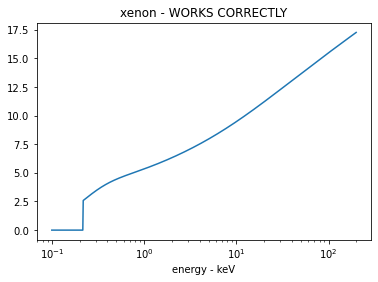

In [6]:
EminXe= 0.1
EmaxXe = 3000
enxe = np.logspace(np.log10(EminXe), np.log10(EmaxXe), 1000)
print(enxe[-1])

plt.title("xenon - WORKS CORRECTLY")
plt.semilogx(enxe, nlyxe(E = enxe, field = 1, interaction = nr))
# plt.semilogx(enxe, nlyxe(E = enxe, field = 1000, interaction = gr))
# plt.semilogx(enxe, nlyxe(E = enxe, field = 5000, interaction = er))
# plt.semilogx(enxe, nlyxe(E = enxe, field = 5000, interaction = nest.ion))
# plt.semilogx(enxe, nlyxe(E = enxe, field = 5000))
plt.xlabel("energy - keV")

In [7]:
nest.ListInteractionTypes()

dict_keys(['nr', 'wimp', 'b8', 'dd', 'ambe', 'cf', 'ion', 'gammaray', 'beta', 'ch3t', 'c14', 'kr83m', 'nonetype'])

Text(0.5, 0, 'energy - keV')

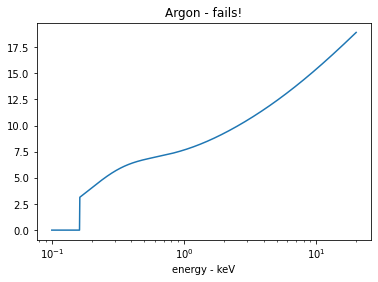

In [8]:
# a.values()
Emin = 0.1 #keV
Emax = 20 #keV
en = np.logspace(np.log10(Emin), np.log10(Emax), 1000)
# en = np.arange(0.1, 20, 1)

plt.semilogx(en, nlyar(E = en, field = 1, interaction = nest.nr, rho = 1.4),)
# plt.semilogx(en, nlyar(E = en, field = 1, interaction = nest.ion),)
# plt.semilogx(en, nlyar(E = en, field = 1, interaction = nest.ambe),)
# plt.semilogx(en, nlyar(E = en, field = 1))
# plt.semilogx(en, nlyar(E = en, field = 2000))

plt.title("Argon - fails!")
plt.xlabel("energy - keV")